# Neuron Model and Network Architecture

1. Single-Input Neuron
2. Transfer Functions
3. Multiple-Input Neuron
4. Layer of Neurons
5. Abbreviated Notation
6. Multilayer Network
7. Abreviated Notation
8. Delays and Integrators
9. Recurrent Network

## 1. Single-Input Neuron


![](images/single_input_neuron.png)

 $$\displaystyle \LARGE \text{p = Scalar Input      }$$
 $$\displaystyle \LARGE \text{w = Scalar Weight}$$
 $$\displaystyle \LARGE \text{b = Bias}$$
 $$\displaystyle \LARGE \text{n = Net Input}$$
 $$\displaystyle \LARGE \text{f = Transfer function}$$
 $$\displaystyle \LARGE \text{a = Scalar output     }$$


![](images/single_input_neuron_statement.png)

In [1]:
#p = Scalar Input 
#w = Scalar Weight   
#b = Bias             
#n = Net Input         
#f = Transfer function 
#a = Scalar output

In [2]:
p = 2
w = 3
b = -1.5

def f(p=0,w=1,b=1):
    return p*w + b
    

a = f(p,w,b)
a



4.5

## 2. Transfer Functions


 1. Hard Limit
 2. Symmetrical Hard Limit
 3. Linear
 4. Saturating Linear
 5. Symmetric Saturating Linear
 6. Log-Sigmoid
 7. Hyperbolic Tangent Sigmoid
 8. Positive Linear
 9. Competitive

In [3]:
!pip install matplotlib numpy

In [4]:
!pip install jupyter-matlab-proxy matlab_kernel

### 1. Hard Limit


$$
\LARGE \operatorname{hardlim}(x)=
\begin{cases}
0 & x<0\\
1 & x\geq 0
\end{cases}
$$



In [5]:
def hardlim(n):
   return (n>=0).astype(int)

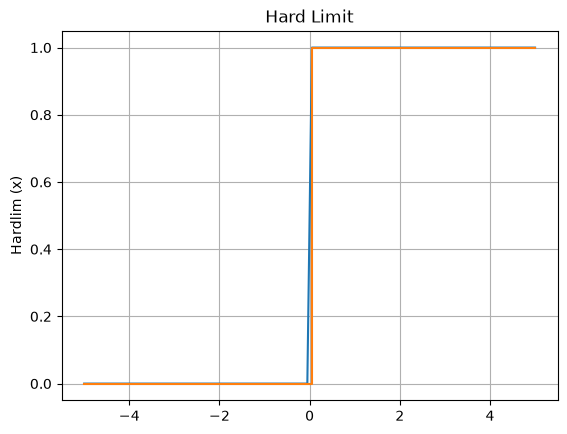

In [6]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = hardlim(x)
plt.plot(x,y)
plt.step(x, y, where="post")
plt.title("Hard Limit")
plt.ylabel("Hardlim (x)")
plt.grid(True)
plt.show()


 ### 2. Symmetrical Hard Limit

 
$$
\LARGE \operatorname{hardlims}(x)=
\begin{cases}
-1 & x<0\\
+1 & x\geq 0
\end{cases}
$$


 

In [7]:
def hardlims(x):
   return (x>=0)*1 + (x<0)*-1

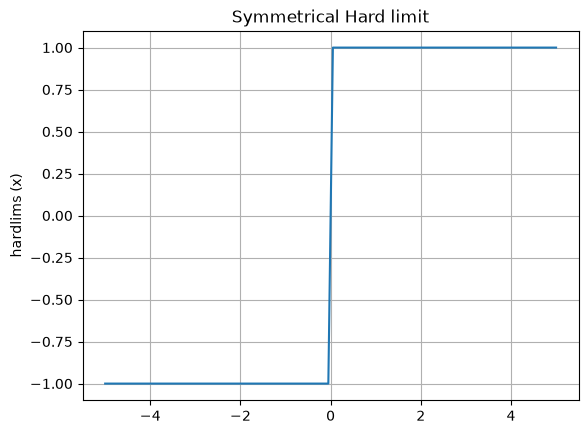

In [8]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = hardlims(x)

#%timeit hardlims(x)

plt.plot(x, y)
plt.title("Symmetrical Hard limit")
plt.ylabel("hardlims (x)")
plt.grid(True)
plt.show()


### 3. Linear

$$
\LARGE  a = n
$$



In [9]:
def purelin(x):
    return x


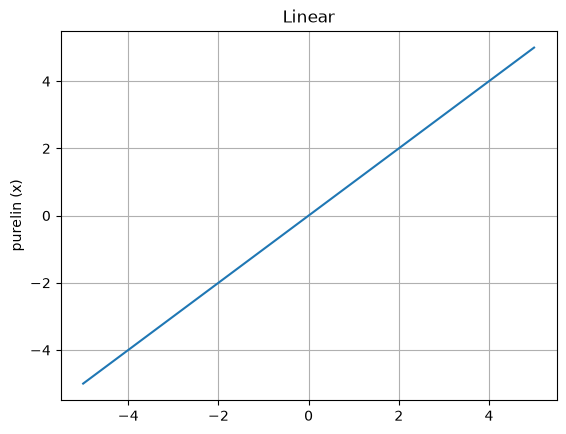

In [10]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = purelin(x)

#%timeit purelin(x)

plt.plot(x, y)
plt.title("Linear")
plt.ylabel("purelin (x)")
plt.grid(True)
plt.show()


### 4. Saturating Linear


$$
\LARGE  \operatorname{satlin}(x)=
\begin{cases}
0 & x<0\\
x & 0\leq x \leq 1 \\
1 & x > 1
\end{cases}
$$



In [11]:
def satlin(x):
    return ((x >= 0) & (x <= 1)) * x + (x < 0) * 0 + (x > 1) * 1


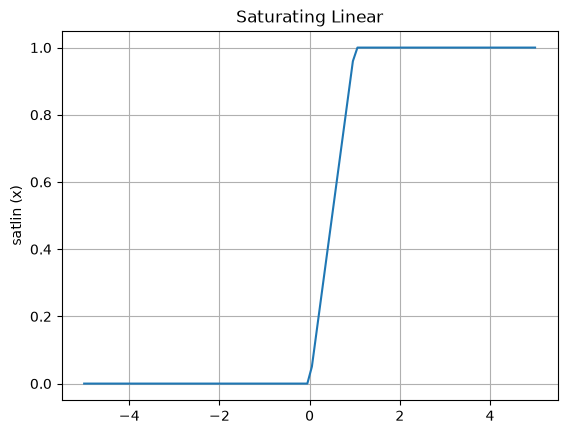

In [12]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = satlin(x)

#%timeit satlin(x)

plt.plot(x, y)
plt.title("Saturating Linear")
plt.ylabel("satlin (x)")
plt.grid(True)
plt.show()


### 5. Symmetric Saturating Linear

$$
\LARGE \operatorname{satlins}(x)=
\begin{cases}
-1 & x< -1 \\
x & -1 \leq x \leq 1 \\
1 & x > 1
\end{cases}
$$


In [13]:
def satlins(x):
    return ((x >= -1) & (x <= 1)) * x + (x < -1) * -1 + (x > 1) * 1


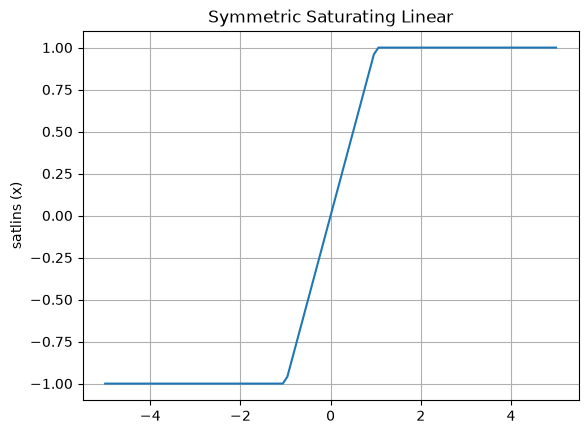

In [14]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = satlins(x)

#%timeit satlins(x)

plt.plot(x, y)
plt.title("Symmetric Saturating Linear")
plt.ylabel("satlins (x)")
plt.grid(True)
plt.show()


### 6. Log-Sigmoid

$$
\LARGE \operatorname{logsig}(x)=
\frac{1}{1+e^{-n}}
$$


In [15]:
import math

def logsig(x):
    #return 1 / (1 + (math.e**(-x)))
    return 1 / (1 + np.exp(-x))
    

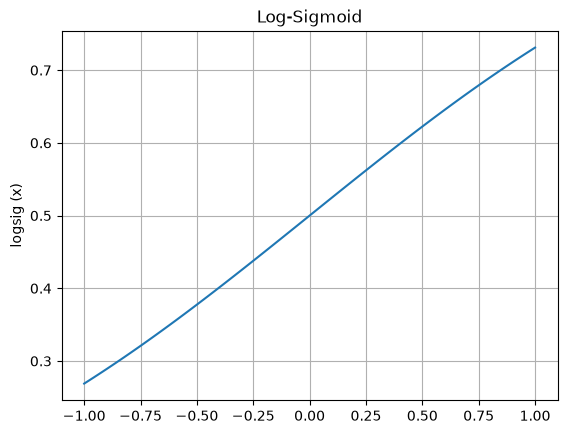

In [16]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-1,1,100)
y = logsig(x)

#%timeit logsig(x)

plt.plot(x, y)
plt.title("Log-Sigmoid")
plt.ylabel("logsig (x)")
plt.grid(True)
plt.show()


### 7. Hyperbolic Tangent Sigmoid

$$
\LARGE \operatorname{tansig}(x)=
\frac{e^n - e^{-n}}{e^n + e^{-n}}
$$


In [17]:
import math

def tansig(x):
    #return ((math.e**x) - (math.e**(-x)))/((math.e**x) + (math.e**(-x)))
    #return (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x))
    return np.tanh(x)

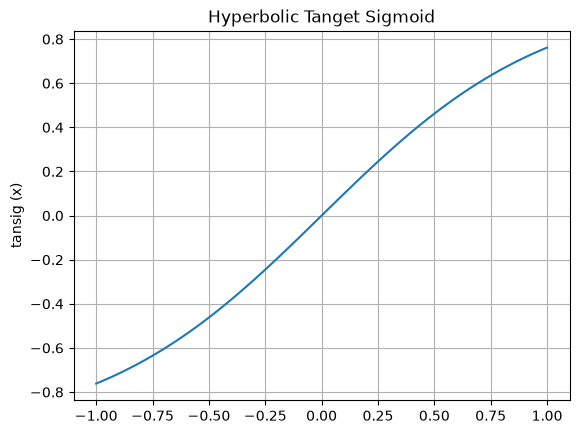

In [18]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-1,1,100)
y = tansig(x)

#%timeit poslin(x)

plt.plot(x, y)
plt.title("Hyperbolic Tanget Sigmoid")
plt.ylabel("tansig (x)")
plt.grid(True)
plt.show()


### 8. Positive Linear

$$
\LARGE  \operatorname{poslin}(x)=
\begin{cases}
0 & x<0 \\
x & 0 \leq x
\end{cases}
$$



In [19]:
def poslin(x):
    return (x >= 0) * x

1.66 μs ± 13.7 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


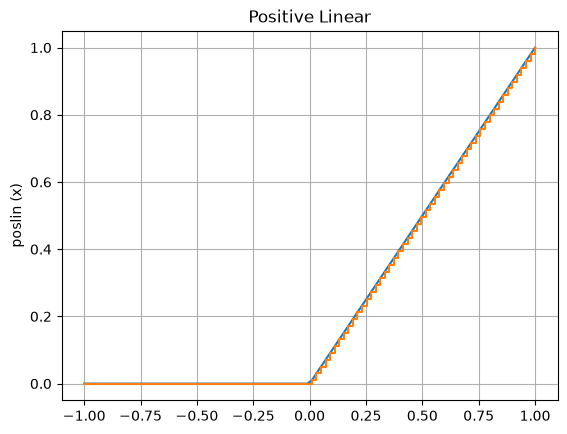

In [20]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-1,1,100)
y = poslin(x)
%timeit poslin(x)

plt.plot(x, y)
plt.step(x, y, where="post")
plt.title("Positive Linear")
plt.ylabel("poslin (x)")
plt.grid(True)
plt.show()


### 9. Competitive
$$
\LARGE \operatorname{compet}(x)=
\begin{cases}
1 & \text{neuron with max n}\\
0 & \text{all other neurons}
\end{cases}
$$


In [21]:
def compet(n):
    y = np.zeros_like(n, dtype=int)
    y[np.argmax(x)] = 1
    return y

2.39 μs ± 37.9 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


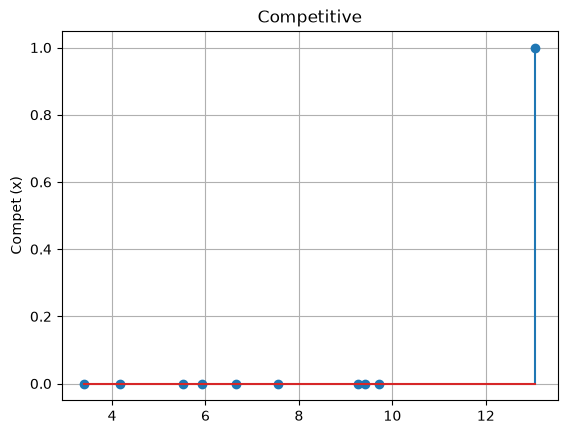

In [22]:
import matplotlib.pyplot as plt
import numpy as np
np.random.seed(123)

#x = np.random.rand(100)
x = np.random.uniform(low=0.5, high=13.3, size=(10,))

y = compet(x)
#plt.hist2d(x,y)
%timeit compet(x)

plt.stem(x, y)
#plt.bar(x, y)
#plt.scatter(x,y)
#plt.step(x, y, where="post")
plt.title("Competitive")
plt.ylabel("Compet (x)")
plt.grid(True)
plt.show()


## 3. Multiple-Input Neuron

![](images/multiple_input_neuron.png)

### Weight Matrix 

A neuron has more than one input. A neuron with $\textbf{R}$ inputs is
shown in Figure 2.5. The individual inputs $p_1, p_2, \cdots, p_R$ are each weighted by
corresponding elements $w_{1,1},w_{1,2},\cdots, w_{1,R}$ of the weight matrix $\textbf{W}$.

he neuron has a bias $b$, which is summed with the weighted inputs to
form the net input $n$:

$$\displaystyle \LARGE n = w_{1,1}p_1 + w_{1,2}p_2 + \cdots + w_{1,R}p_R + b$$

This expression can be written in matrix form:

$$ \LARGE n = \textbf{Wp} +b $$

where the matrix $\textbf{W}$ for the single neuron case has only one row.

$$\LARGE a = f(\textbf{Wp}+b)$$

Fortunately, $\LARGE \textbf{neural networks can often be described with matrices}$. This
kind of matrix expression will be used throughout the book. Don’t be con-
cerned if you are rusty with matrix and vector operations. $\LARGE \textbf{We will review
these topics in Chapters 5 and 6}$, and we will provide many examples and
solved problems that will spell out the procedures.


In [23]:
import numpy as np

np.random.seed(23)

neuron_length = 4


w = np.random.rand(neuron_length) # Weight
print(f"Weight (W) = {w}")
print(f"Weight (W) - Dimentsion = {w.shape}")

p = np.linspace(-10,10,neuron_length)
print(f"Input (p) = {p}")
print(f"Input (p) - Dimentsion = {w.shape}")

Wp = np.dot(w,p)
print(f"Wp = {Wp}")

b = 1 

Wp_add_b = Wp + b

print(f"a = f(Wp + 1) = {Wp_add_b}")

n = tansig(np.array(Wp_add_b))

print(f"a = tansig(Wp + 1) = {n}")


Weight (W) = [0.51729788 0.9469626  0.76545976 0.28239584]
Weight (W) - Dimentsion = (4,)
Input (p) = [-10.          -3.33333333   3.33333333  10.        ]
Input (p) - Dimentsion = (4,)
Wp = -2.9540298801877887
a = f(Wp + 1) = -1.9540298801877887
a = tansig(Wp + 1) = -0.9606316493691667


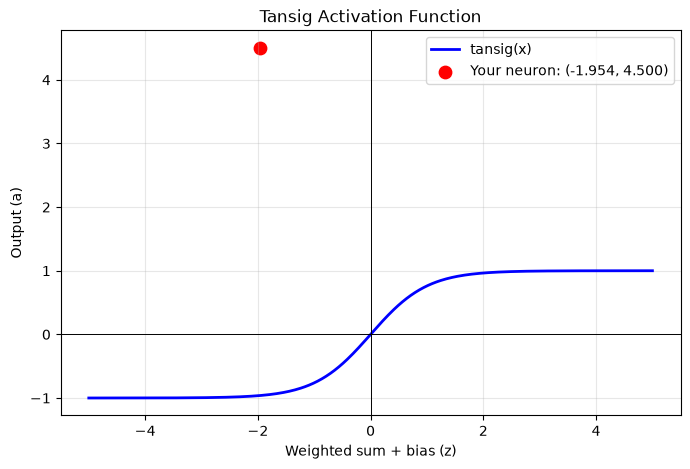

In [24]:

import numpy as np
import matplotlib.pyplot as plt


x = np.linspace(-5, 5, 400)
y = tansig(x)

plt.figure(figsize=(8, 5))
plt.plot(x, y, color="blue", linewidth=2, label="tansig(x)")
plt.axhline(0, color="black", linewidth=0.7)
plt.axvline(0, color="black", linewidth=0.7)
plt.scatter([Wp_add_b], [a], color="red", s=80,
            label=f"Your neuron: ({Wp_add_b:.3f}, {a:.3f})")
plt.xlabel("Weighted sum + bias (z)")
plt.ylabel("Output (a)")
plt.title("Tansig Activation Function")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [25]:
import sys
import struct

print("Python Version:", sys.version)
print("Architecture Bit Depth:", struct.calcsize('P') * 8)


Python Version: 3.12.15 (main, Oct 13 2026, 16:52:04) [GCC 15.3.0]
Architecture Bit Depth: 64


In [26]:
#!pip install tensorflow visualkeras 

In [27]:
#!pip install --index-url https://download.pytorch.org/whl/cpu

In [28]:
#!pip install graphviz

Weights: [0.51729788 0.9469626  0.76545976 0.28239584]
Inputs: [-10.          -3.33333333   3.33333333  10.        ]
Wp: -2.9540298801877887
Wp + b: -1.9540298801877887
tansig(Wp + b): -0.9606316493691667


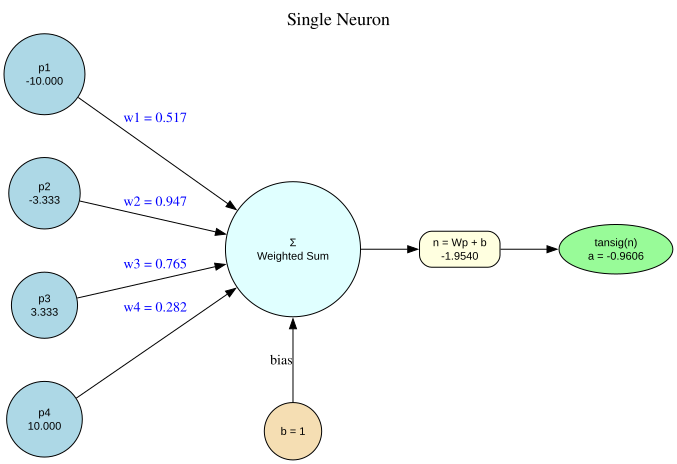

In [40]:

import numpy as np
from graphviz import Digraph
from IPython.display import Image, display


class NeuronVisualizer:
    def __init__(self, w, p, b=1):
        self.w = np.asarray(w, dtype=float)
        self.p = np.asarray(p, dtype=float)
        self.b = b

        if self.w.ndim != 1 or self.p.ndim != 1:
            raise ValueError("Weights and inputs must be 1D arrays.")

        if len(self.w) != len(self.p):
            raise ValueError("Weights and inputs must have equal lengths.")

        self.Wp = np.dot(self.w, self.p)
        self.net_input = self.Wp + self.b
        self.a = np.tanh(self.net_input)

     
    def visualize(self, filename="neuron_visualization"):
     dot = Digraph("Neuron", format="png")

     dot.attr(
        rankdir="LR",
        splines="true",
        nodesep="0.6",
        ranksep="0.8",
        label="Single Neuron",
        labelloc="t",
        fontsize="18"
     )

     dot.attr("node", fontname="Arial", fontsize="11")

     # Input nodes
     for i, p_i in enumerate(self.p, start=1):
        dot.node(
            f"p{i}", f"p{i}\n{p_i:.3f}",
            shape="circle", style="filled",
            fillcolor="lightblue"
        )

     # Summation neuron
     dot.node(
            "sum",
            "Σ\nWeighted Sum",
            shape="circle",
            style="filled",
            fillcolor="lightcyan"
     )

     


     # Weighted input connections: left to right
     for i, w_i in enumerate(self.w, start=1):
        dot.edge(
            f"p{i}", "sum",
            label=f"w{i} = {w_i:.3f}",
            fontcolor="blue"
        )

     # Bias placed above the summation neuron
     dot.node(
        "bias", f"b = {self.b}",
        shape="circle", style="filled",
        fillcolor="wheat"
     )

     # Force bias above sum and connect vertically
     dot.edge(
        "bias", "sum",
        label="bias",
        constraint="false",
        minlen="1"
    )

     with dot.subgraph() as s:
        s.attr(rank="same")
        s.node("bias")
        s.node("sum")

     # Net input and activation
     dot.node(
        "net",
        f"n = Wp + b\n{self.net_input:.4f}",
        shape="box", style="rounded,filled",
        fillcolor="lightyellow"
     )

     dot.edge("sum", "net")

     dot.node(
        "activation",
        f"tansig(n)\na = {self.a:.4f}",
        shape="ellipse", style="filled",
        fillcolor="palegreen"
     )

     dot.edge("net", "activation")

     # Render in Jupyter without an external viewer
     output = dot.render(
        filename=filename,
        view=False,
        cleanup=True
     )

     from IPython.display import Image, display
     #display(Image(filename=output))

     return dot



# Example
np.random.seed(23)

neuron_length = 4
w = np.random.rand(neuron_length)
p = np.linspace(-10, 10, neuron_length)
b = 1

neuron = NeuronVisualizer(w, p, b)

print("Weights:", w)
print("Inputs:", p)
print("Wp:", neuron.Wp)
print("Wp + b:", neuron.net_input)
print("tansig(Wp + b):", neuron.a)

neuron.visualize()


### Weight Indices

We have adopted a particular convention in **assigning the indices of the elements of the weight matrix**. The $\textbf{first index}$ indicates $\textbf{the particular neuron destination for that weight}$.
The **second index** indicates **the source of the signal fed to the neuron**. Thus, the indices in $w_{1,2}$ say that this weight represents **the connection to the first (and only) neuron from the second
source**. Of course, **this convention** is **more useful if there is more than one
neuron**, as will be the case later in this chapter.

### Abbreviated Notation

We would **like to draw networks with several neurons, each having several
inputs**. Further, we would like to have more than one layer of neurons. **You
can imagine how complex such a network might appear if all the lines were
drawn**. It would **take a lot of ink**, could **hardly be read**, and **the mass of detail might obscure the main features**. **Thus**, we will **use an abbreviated notation**. A multiple-input neuron using this notation is shown in **Figure 2.6**.

![](images/multiple_input_neuron_abbr.png)

As shown in Figure 2.6, $\colorbox{yellow}{$\text{ the input vector  \textbf{P} is represented by the solid vertical bar at the left}$}$. The dimensions of $\textbf{P}$ are displayed below the variable as $\mathbf{R \times 1}$, indicating that the input is a single vector of $\textbf{R}$elements. These
inputs go to the weight matrix $\textbf{W}$, which has $\textbf{R}$ columns but only one row
in this single neuron case. A constant 1 enters the neuron as an input and
is multiplied by a scalar bias $\textbf{b}$. The net input to the transfer function $\textbf{f}$ is $\textbf{n}$
, which is the sum of the bias $\textbf{b}$ and the product $\textbf{Wp}$. The neuron’s output $\textbf{a}$
is a scalar in this case. If we had more than one neuron, the network output would be a vector.

The dimensions of the variables in these abbreviated notation figures will
always be included, so that you can tell immediately if we are talking about
a scalar, a vector or a matrix. You will not have to guess the kind of variable
or its dimensions.

**Note**: that the number of inputs to a network is set by the external specifications of the problem. If, for instance, $\LARGE \textbf{you want to design a neural network
that is to predict}$ kite-flying conditions and the inputs are air temperature,
wind velocity and humidity, then there would be three inputs to the network.